# Deeper Analysis of Moodle Activity (2019–2026)

This notebook continues `01a_activity_analysis.ipynb`. It investigates the 2024 activity peak and subsequent decline, the March 2020 transition to remote teaching, and student activity around homework deadlines and examinations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

## 1. Data preparation

We load Moodle event logs from 2019–2026 and combine them into one dataset.

Student and teacher activities are separated using their actor IDs.


In [2]:
# Path to the original dataset
DATA_DIR = Path("tcs_dataset/data")

# Load events from all years
events_list = []

for year in range(2019, 2027):
    df = pd.read_parquet(DATA_DIR / str(year) / "events.parquet")
    df["year"] = year
    events_list.append(df)

events = pd.concat(events_list, ignore_index=True)

# Separate students and teachers
students = events[events["actor_id"].str.startswith("S", na=False)].copy()
teachers = events[events["actor_id"] == "T"].copy()

print("Total events:", len(events))
print("Student events:", len(students))
print("Teacher events:", len(teachers))

display(events.head())

Total events: 972372
Student events: 733090
Teacher events: 239282


,course_run_id,event_id,event_time,actor_id,affected_actor_id,event_context,component,event_name,origin,year
0,TCS_2019,E_2019_000001,2019-02-11 12:17:00+02:00,T,NaN,Course: Introduction to Theoretical Computer S...,System,Course viewed,web,2019
1,TCS_2019,E_2019_000002,2019-02-11 12:17:00+02:00,T,NaN,Course: Introduction to Theoretical Computer S...,Logs,Log report viewed,web,2019
2,TCS_2019,E_2019_000003,2019-02-11 12:17:00+02:00,T,NaN,Course: Introduction to Theoretical Computer S...,System,Course viewed,web,2019
3,TCS_2019,E_2019_000004,2019-02-11 12:17:00+02:00,T,NaN,URL: Syllabus,System,Course module updated,web,2019
4,TCS_2019,E_2019_000005,2019-02-11 12:18:00+02:00,T,NaN,URL: Information page in Courses,System,Course module updated,web,2019


In [3]:
# Verify that all eight years were loaded
display(
    events.groupby("year")
    .size()
    .rename("Total events")
    .to_frame()
)

,Total events
year,
2019,68072
2020,122142
2021,183166
2022,97830
2023,121861
2024,157788
2025,112864
2026,108649


## 2. Changes in Moodle activity during 2023–2026

We investigate which specific Moodle events contributed to the 2024 activity peak and the changes that followed. Student and teacher events are analysed separately because they represent different activities.

### 2.1 Changes in student activity: raw event counts

First, we compare event counts across 2023–2026 to identify the largest changes. Because cohorts vary in size, these counts are descriptive; the next subsection compares events per enrolled student.

In [4]:
# Count student events by type and year
student_changes = pd.crosstab(
    students["event_name"],
    students["year"]
)

# Keep the years relevant to this analysis
student_changes = student_changes[[2023, 2024, 2025, 2026]].copy()

# Calculate year-to-year changes
student_changes["Change 2023–2024"] = (
    student_changes[2024] - student_changes[2023]
)

student_changes["Change 2024–2025"] = (
    student_changes[2025] - student_changes[2024]
)

student_changes["Change 2025–2026"] = (
    student_changes[2026] - student_changes[2025]
)

# Show activities with the largest decreases from 2024 to 2025
display(
    student_changes.sort_values("Change 2024–2025").head(15)
)

year,2023,2024,2025,2026,Change 2023–2024,Change 2024–2025,Change 2025–2026
event_name,,,,,,,
Quiz attempt viewed,17639,20820,1778,1620,3181,-19042,-158
Quiz attempt updated,0,16725,927,860,16725,-15798,-67
Course user report viewed,4141,7520,2791,1752,3379,-4729,-1039
Course viewed,22655,26327,21788,19908,3672,-4539,-1880
Quiz attempt reviewed,4613,4599,1772,1266,-14,-2827,-506
Course module viewed,24673,29218,26573,29054,4545,-2645,2481
Quiz attempt started,1487,1826,831,821,339,-995,-10
Quiz attempt summary viewed,1542,1846,933,849,304,-913,-84
Quiz attempt submitted,1167,1467,734,726,300,-733,-8


### 2.2 Changes in student activity per enrolled student

To account for differences in cohort size, we divide each year's event counts by its number of enrolled students. We use these normalised values to examine which event types changed most from 2024 to 2025, while retaining the other two year-to-year comparisons for context.

In [5]:
# Load course information containing enrolled student counts
course_runs = pd.read_csv(DATA_DIR / "course_runs.csv")

# Extract year from the course run ID
course_runs["year"] = course_runs["course_run_id"].str[-4:].astype(int)

# Create a mapping of year to enrolled student count
student_counts = course_runs.set_index("year")["student_count"]

# Normalise event counts by enrolled students
student_changes_per_student = student_changes[
    [2023, 2024, 2025, 2026]
].div(student_counts.loc[2023:2026], axis=1)


# Calculate year-to-year changes
student_changes_per_student["Change 2023–2024"] = (
    student_changes_per_student[2024] -
    student_changes_per_student[2023]
)

student_changes_per_student["Change 2024–2025"] = (
    student_changes_per_student[2025] -
    student_changes_per_student[2024]
)

student_changes_per_student["Change 2025–2026"] = (
    student_changes_per_student[2026] -
    student_changes_per_student[2025]
)

# Display the largest decreases per enrolled student
display(
    student_changes_per_student
    .sort_values("Change 2024–2025")
    .head(15)
    .round(2)
)

year,2023,2024,2025,2026,Change 2023–2024,Change 2024–2025,Change 2025–2026
event_name,,,,,,,
Quiz attempt viewed,166.41,174.96,12.98,11.41,8.55,-161.98,-1.57
Quiz attempt updated,0.00,140.55,6.77,6.06,140.55,-133.78,-0.71
Course viewed,213.73,221.24,159.04,140.20,7.51,-62.20,-18.84
Course module viewed,232.76,245.53,193.96,204.61,12.77,-51.57,10.64
Course user report viewed,39.07,63.19,20.37,12.34,24.13,-42.82,-8.03
Quiz attempt reviewed,43.52,38.65,12.93,8.92,-4.87,-25.71,-4.02
Quiz attempt started,14.03,15.34,6.07,5.78,1.32,-9.28,-0.28
Quiz attempt summary viewed,14.55,15.51,6.81,5.98,0.97,-8.70,-0.83
Quiz attempt submitted,11.01,12.33,5.36,5.11,1.32,-6.97,-0.24


#### Largest decreases in recorded events per student, 2024–2025

The chart highlights the ten event types with the largest negative changes in average event counts per enrolled student.

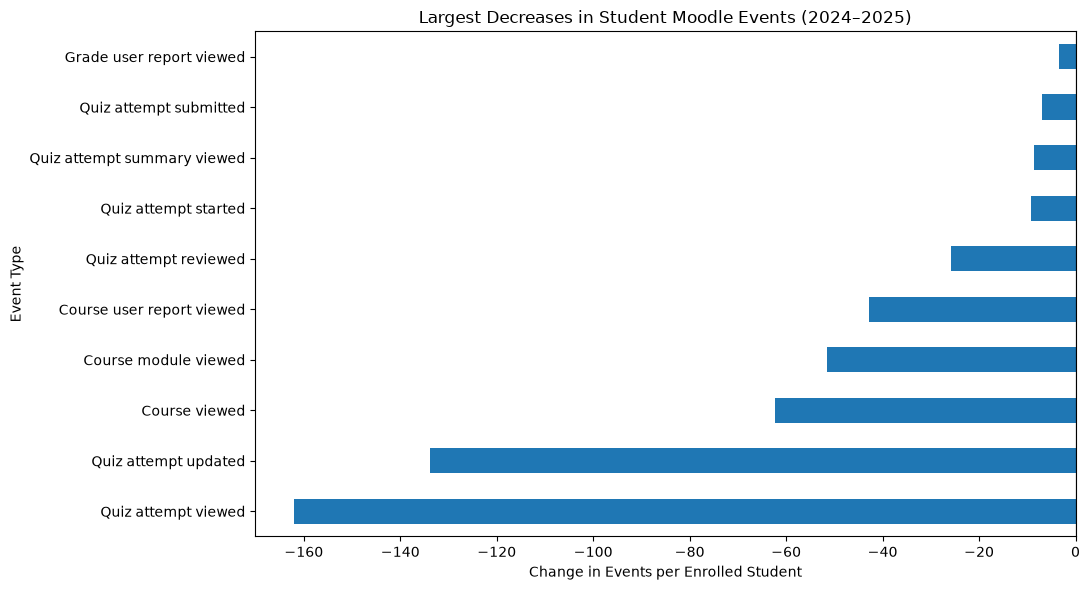

In [6]:
# Select the 10 largest decreases
largest_decreases = (
    student_changes_per_student["Change 2024–2025"]
    .nsmallest(10)
    .sort_values()
)

# Create horizontal bar chart
plt.figure(figsize=(11, 6))

largest_decreases.plot(kind="barh")

plt.title("Largest Decreases in Student Moodle Events (2024–2025)")
plt.xlabel("Change in Events per Enrolled Student")
plt.ylabel("Event Type")
plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()


#### Interpretation

The 2024–2025 decline remained substantial after adjusting for cohort size. `Quiz attempt viewed` fell by about 162 events per enrolled student, `Quiz attempt updated` by 134, `Course viewed` by 62, and `Course module viewed` by 52.

The drop therefore affected both quiz interactions and course navigation. The next subsection looks specifically at the preceding 2023–2024 increase.

### 2.3 Investigating the 2024 activity peak

We now examine which student Moodle events increased most between 2023 and 2024.

By comparing events per enrolled student, we can identify which activities contributed to the unusually high activity in 2024 while accounting for differences in cohort size.

event_name
Course module instance list viewed      1.31
Quiz attempt started                    1.32
Quiz attempt submitted                  1.32
Course viewed                           7.51
Discussion updated                      8.01
Quiz attempt viewed                     8.55
Grade user report viewed                9.21
Course module viewed                   12.77
Course user report viewed              24.13
Quiz attempt updated                  140.55
Name: Change 2023–2024, dtype: float64

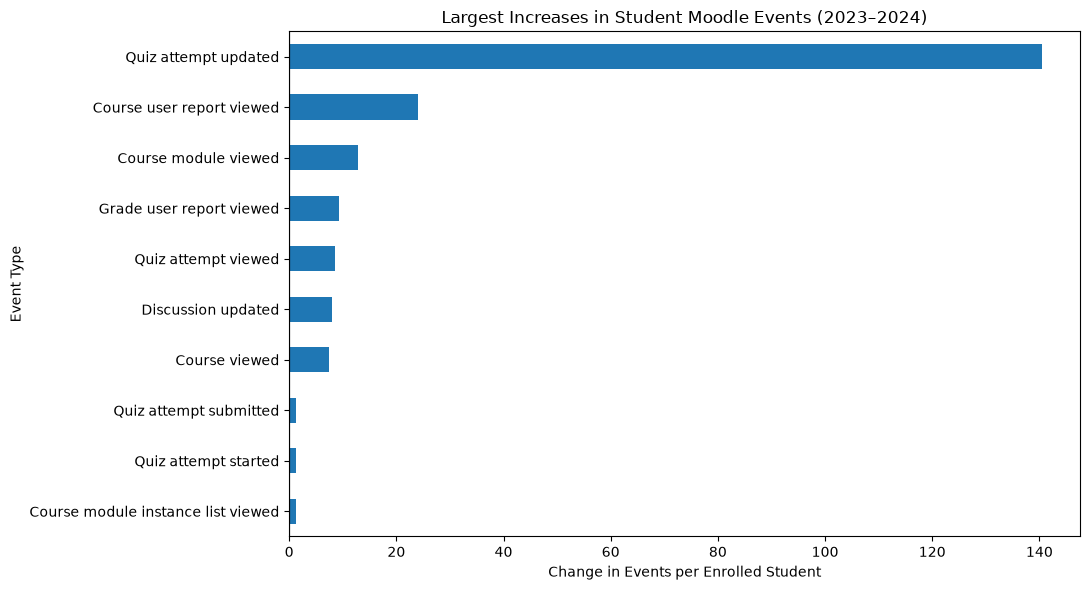

In [7]:
# Find the 10 largest increases from 2023 to 2024
largest_increases = (
    student_changes_per_student["Change 2023–2024"]
    .nlargest(10)
    .sort_values()
)

display(largest_increases.round(2))

plt.figure(figsize=(11, 6))

largest_increases.plot(kind="barh")

plt.title("Largest Increases in Student Moodle Events (2023–2024)")
plt.xlabel("Change in Events per Enrolled Student")
plt.ylabel("Event Type")
plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()


#### Interpretation

The 2023–2024 increase was dominated by `Quiz attempt updated`, which rose by approximately 141 events per enrolled student after being absent from the 2023 logs. Course-report and module viewing also increased, but by much smaller amounts.

Quiz starts and submissions rose only slightly compared with quiz updates. This makes the appearance of that event type important when interpreting the unusually high 2024 total.

### 2.4 Changes in student activity from 2025 to 2026

We examine whether the changes observed after the 2024 peak continued in 2026 or whether some activities began to recover.


In [8]:
# Compare the largest changes between 2025 and 2026
student_2026_changes = student_changes_per_student[
    [2025, 2026, "Change 2025–2026"]
].copy()

# Sort by the size of the change, regardless of direction
student_2026_changes = student_2026_changes.reindex(
    student_2026_changes["Change 2025–2026"]
    .abs()
    .sort_values(ascending=False)
    .index
)

display(student_2026_changes.head(12).round(2))

year,2025,2026,Change 2025–2026
event_name,,,
Course viewed,159.04,140.20,-18.84
Course module viewed,193.96,204.61,10.64
Course user report viewed,20.37,12.34,-8.03
The status of the submission has been viewed.,42.16,36.54,-5.62
Feedback viewed,11.16,6.91,-4.25
Quiz attempt reviewed,12.93,8.92,-4.02
Grade user report viewed,42.86,44.98,2.12
Course module instance list viewed,3.33,1.57,-1.76
Discussion updated,14.85,13.12,-1.73


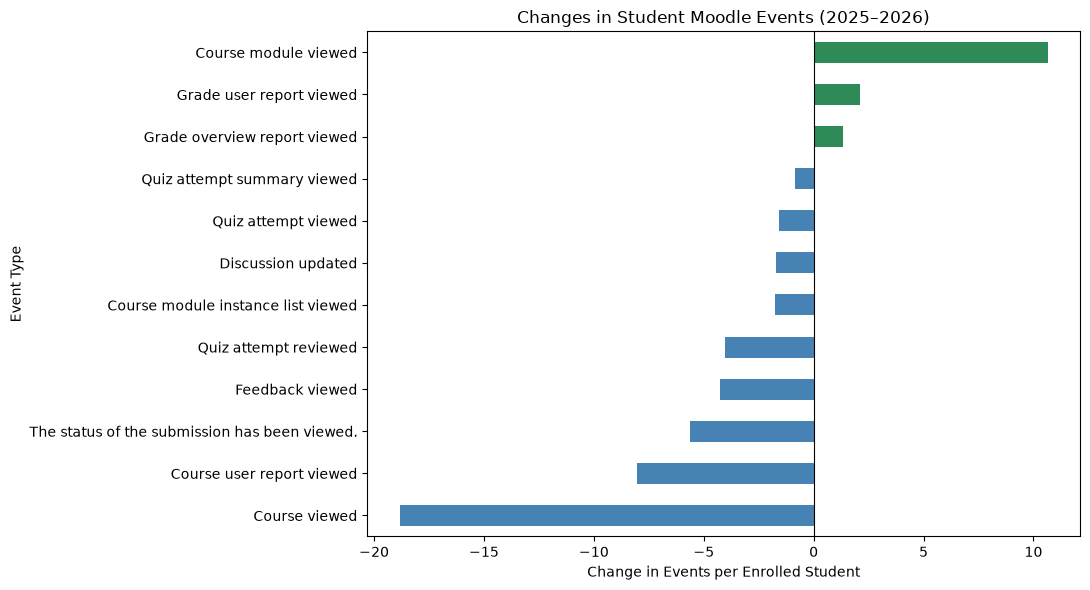

In [9]:
# Select the 12 largest changes (in either direction)
largest_changes_2026 = (
    student_2026_changes["Change 2025–2026"]
    .head(12)
    .sort_values()
)

# Visualise increases and decreases
plt.figure(figsize=(11, 6))

colors = [
    "seagreen" if value > 0 else "steelblue"
    for value in largest_changes_2026
]

largest_changes_2026.plot(
    kind="barh",
    color=colors
)

plt.title("Changes in Student Moodle Events (2025–2026)")
plt.xlabel("Change in Events per Enrolled Student")
plt.ylabel("Event Type")
plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

#### Interpretation

Changes between 2025 and 2026 were smaller and more mixed than in the previous transition. Course-page viewing fell by about 18.8 events per enrolled student, while course-module viewing increased by about 10.6. Most quiz-related events declined slightly, but some grade-report views increased. There was no uniform decrease across all activities.

### 2.5 Changes in teacher activity

We compare teacher Moodle events per teacher from 2023 to 2026 to identify which activities contributed most to changes in recorded teaching activity.

In [10]:
# Count teacher events by type and year
teacher_changes = pd.crosstab(
    teachers["event_name"],
    teachers["year"]
)[[2023, 2024, 2025, 2026]]

# Number of teachers in each year
teacher_counts = course_runs.set_index("year")["teacher_count"]

# Calculate events per teacher
teacher_changes_per_teacher = teacher_changes.div(
    teacher_counts.loc[2023:2026],
    axis=1
)

# Calculate year-to-year changes
for start, end in [(2023, 2024), (2024, 2025), (2025, 2026)]:
    teacher_changes_per_teacher[f"Change {start}–{end}"] = (
        teacher_changes_per_teacher[end]
        - teacher_changes_per_teacher[start]
    )

# Display the largest changes from 2024 to 2025
display(
    teacher_changes_per_teacher.reindex(
        teacher_changes_per_teacher["Change 2024–2025"]
        .abs().sort_values(ascending=False).head(12).index
    ).round(1)
)

year,2023,2024,2025,2026,Change 2023–2024,Change 2024–2025,Change 2025–2026
event_name,,,,,,,
Quiz attempt reviewed,45.4,380.1,5.7,11.2,334.8,-374.5,5.5
Grade item updated,376.5,109.4,436.2,67.3,-267.1,326.8,-368.8
Course module viewed,645.0,664.4,934.7,808.5,19.4,270.3,-126.2
Grading form viewed,308.6,436.2,666.5,670.8,127.6,230.2,4.3
Question manually graded,175.4,218.1,0.0,2.7,42.8,-218.1,2.7
User graded,293.4,484.5,702.2,306.8,191.1,217.7,-395.3
The submission has been graded.,376.6,407.2,607.7,558.0,30.6,200.4,-49.7
Grading table viewed,343.6,379.6,568.8,493.0,36.0,189.2,-75.8
Quiz report viewed,176.0,123.8,38.0,21.0,-52.2,-85.8,-17.0


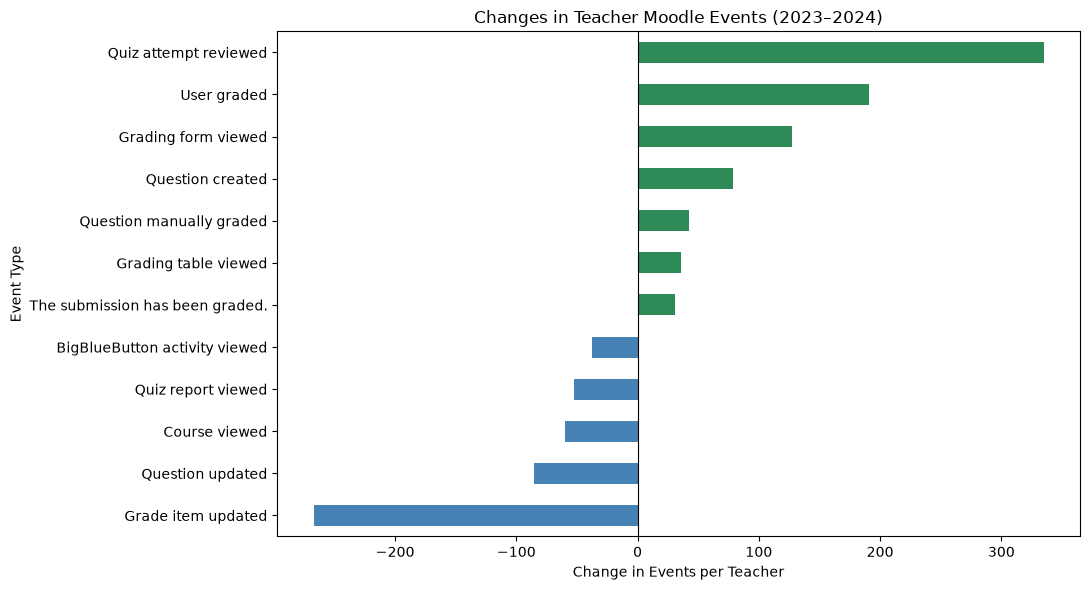

In [11]:
# Select the 12 largest changes from 2023 to 2024
teacher_largest_changes = (
    teacher_changes_per_teacher["Change 2023–2024"]
    .loc[lambda x: x.abs().nlargest(12).index]
    .sort_values()
)

plt.figure(figsize=(11, 6))

teacher_largest_changes.plot(
    kind="barh",
    color=[
        "seagreen" if x > 0 else "steelblue"
        for x in teacher_largest_changes
    ]
)

plt.title("Changes in Teacher Moodle Events (2023–2024)")
plt.xlabel("Change in Events per Teacher")
plt.ylabel("Event Type")
plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

#### Interpretation

Between 2023 and 2024, the largest increase in teacher activity occurred in "Quiz attempt reviewed" (+334.8 events per teacher). "User graded" and "Grading form viewed" also increased, suggesting more recorded activity related to reviewing and assessing student work.

However, "Grade item updated" decreased considerably (−267.1 events per teacher), along with some question-editing and course-viewing activities.

These results suggest a change in how teachers interacted with Moodle's assessment tools rather than a uniform increase in teaching activity. Differences in assessment practices or event logging may have contributed to these patterns.

Text(0, 0.5, 'Event Type')

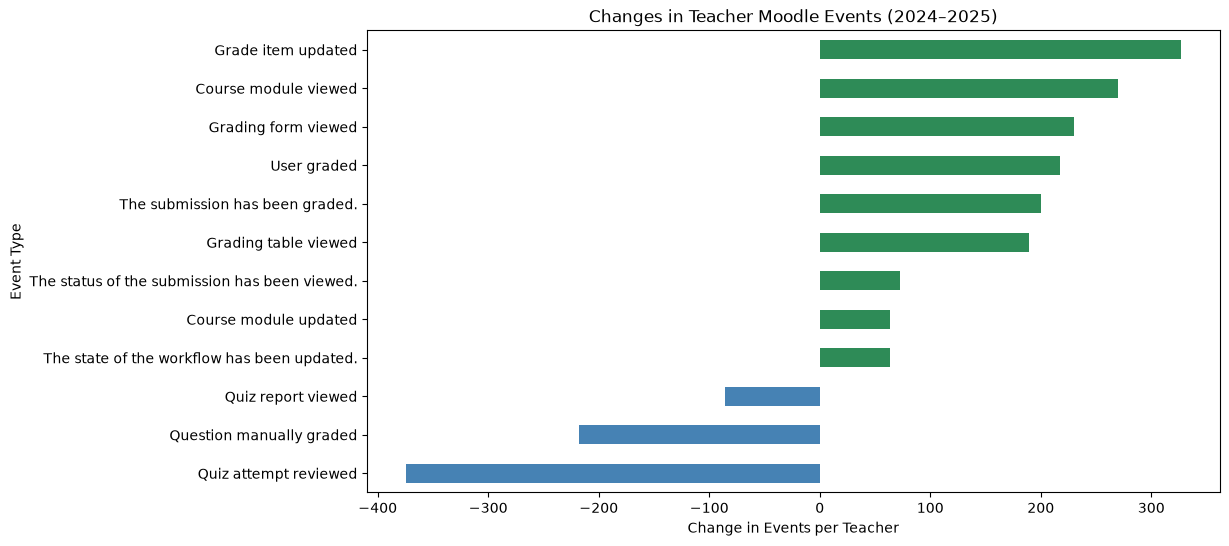

In [12]:
# Select the 12 largest changes from 2024 to 2025
teacher_largest_changes = (
    teacher_changes_per_teacher["Change 2024–2025"]
    .loc[lambda x: x.abs().nlargest(12).index]
    .sort_values()
)

plt.figure(figsize=(11, 6))

teacher_largest_changes.plot(
    kind="barh",
    color=[
        "seagreen" if x > 0 else "steelblue"
        for x in teacher_largest_changes
    ]
)

plt.title("Changes in Teacher Moodle Events (2024–2025)")
plt.xlabel("Change in Events per Teacher")
plt.ylabel("Event Type")

#### Interpretation

Between 2024 and 2025, teacher Moodle activity shifted noticeably. "Quiz attempt reviewed" decreased by 374.5 events per teacher, while "Question manually graded" decreased by 218.1, indicating fewer recorded interactions with quiz assessment tools.

Meanwhile, "Grade item updated" increased by 326.8 events per teacher, and course module viewing, grading form viewing and submission-related activities also increased.

These contrasting patterns suggest a shift in recorded assessment activity from quiz-related interactions toward other grading and submission-management activities. However, differences in Moodle logging or assessment practices may also explain part of this change.

Text(0, 0.5, 'Event Type')

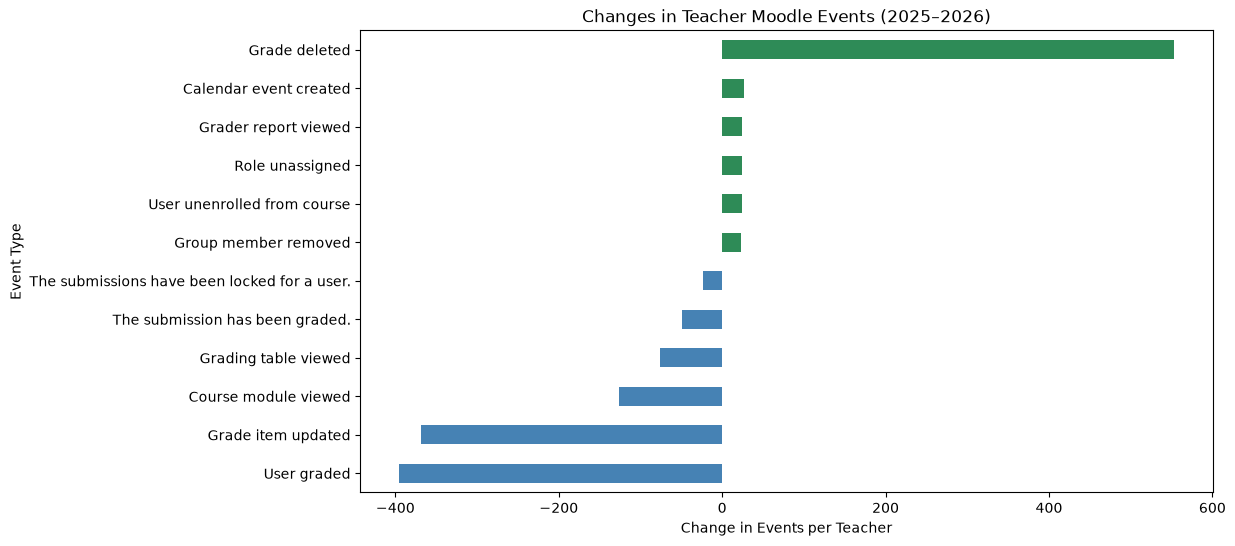

In [13]:
# Select the 12 largest changes from 2025 to 2026
teacher_largest_changes = (
    teacher_changes_per_teacher["Change 2025–2026"]
    .loc[lambda x: x.abs().nlargest(12).index]
    .sort_values()
)

plt.figure(figsize=(11, 6))

teacher_largest_changes.plot(
    kind="barh",
    color=[
        "seagreen" if x > 0 else "steelblue"
        for x in teacher_largest_changes
    ]
)

plt.title("Changes in Teacher Moodle Events (2025–2026)")
plt.xlabel("Change in Events per Teacher")
plt.ylabel("Event Type")

#### Interpretation

Between 2025 and 2026, several teacher grading activities decreased substantially. "User graded" declined by approximately 395 events per teacher, while "Grade item updated" decreased by around 369.

In contrast, "Grade deleted" increased sharply, becoming the largest positive change. This unusual increase may reflect changes in grading procedures, course administration or Moodle logging. It does not necessarily mean that teachers manually deleted more student grades.

Overall, teacher activity continued to change in 2026, particularly in grading-related events. However, the unusually large increase in grade deletion events requires further investigation before drawing conclusions about its cause.

### 2.6 Overall findings

The analysis revealed different patterns in student and teacher Moodle activity between 2023 and 2026.

For students, the unusually high activity in 2024 was mainly associated with a sharp increase in "Quiz attempt updated" events. In 2025, both quiz-related interactions and course navigation decreased substantially, while changes in 2026 were generally smaller.

Teacher activity followed a different pattern. Quiz reviewing increased in 2024, while several other grading activities decreased. In 2025, quiz-related events declined as other grading and submission-management activities increased. The following year showed another shift, including a substantial increase in "Grade deleted" events.

Overall, the findings show that changes in Moodle activity were driven by specific event types rather than uniform increases or decreases across all activities. Student and teacher activity also followed different patterns, highlighting the value of analysing them separately.


## 3. COVID-19 Transition (2020)

On March 16, 2020, the course transitioned from in-person to remote teaching due to COVID-19.

We examine how student and teacher Moodle activity changed around this date, focusing on daily event counts and activity patterns before and after the transition.

### 3.1 Daily Moodle activity around the transition

We visualise daily student and teacher events to identify changes in Moodle activity around March 16, 2020.

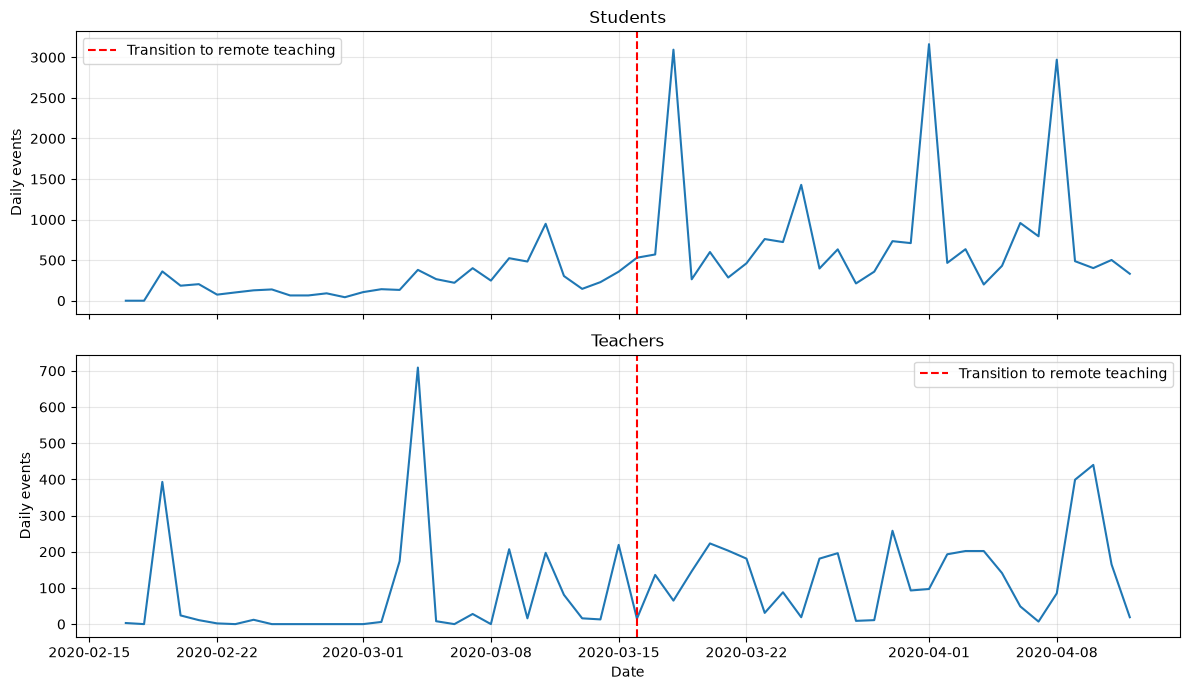

In [14]:
# Select events from February 17 to April 12, 2020
covid_events = events[
    (events["year"] == 2020) &
    (events["event_time"].between(
        "2020-02-17", "2020-04-12 23:59:59"
    ))
].copy()

# Extract dates without timezone information
covid_events["date"] = (
    covid_events["event_time"]
    .dt.tz_localize(None)
    .dt.normalize()
)

covid_events["actor_type"] = np.where(
    covid_events["actor_id"] == "T",
    "Teachers",
    "Students"
)

# Count daily events
daily_activity = (
    covid_events.groupby(["date", "actor_type"])
    .size()
    .unstack(fill_value=0)
)

daily_activity = daily_activity.reindex(
    pd.date_range("2020-02-17", "2020-04-12"),
    fill_value=0
)

# Plot student and teacher activity
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for ax, actor in zip(axes, ["Students", "Teachers"]):
    ax.plot(daily_activity.index, daily_activity[actor])
    ax.axvline(
        pd.Timestamp("2020-03-16"),
        color="red",
        linestyle="--",
        label="Transition to remote teaching"
    )
    ax.set_ylabel("Daily events")
    ax.set_title(actor)
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

#### Interpretation

Student Moodle activity increased noticeably after the transition to remote teaching on March 16, 2020. Before the transition, daily event counts were generally lower, while afterward several days exceeded 3,000 events. This suggests that students relied more heavily on Moodle during remote teaching.

Teacher activity showed a less consistent pattern. Large fluctuations were present both before and after March 16, without an equally clear increase in daily activity.

The student activity peaks may be related to assignment deadlines or assessments. Further analysis of the course calendar will help distinguish these effects from changes associated with the transition to remote teaching.

In [15]:
# Compare 28 days before and after the transition
transition = pd.Timestamp("2020-03-16")

before = daily_activity.loc[
    transition - pd.Timedelta(days=28):
    transition - pd.Timedelta(days=1)
]

after = daily_activity.loc[
    transition:
    transition + pd.Timedelta(days=27)
]

comparison = pd.DataFrame({
    "Before (events/day)": before.mean(),
    "After (events/day)": after.mean()
})

comparison["Change (%)"] = (
    (comparison["After (events/day)"] /
     comparison["Before (events/day)"] - 1) * 100
)

display(comparison.round(1))

,Before (events/day),After (events/day),Change (%)
actor_type,,,
Students,226.7,825.0,264.0
Teachers,75.7,137.6,81.9


#### Interpretation

In the four weeks after March 16, 2020, average daily student activity rose from 226.7 to 825.0 events (+264%). Teacher activity rose from 75.7 to 137.6 events/day (+81.9%). The daily chart also shows more pronounced student peaks after the transition, whereas teacher activity was irregular on both sides of the date.

This is a before/after association, not a controlled estimate of the effects of COVID-19: the semester and its assessment schedule were also progressing.

### 3.3 Changes in student activity types

We compare the frequency of individual Moodle events during the four weeks before and after March 16, 2020, to identify which activities contributed most to the increase in student activity.


In [16]:
# Assign each event to the before/after period
transition = pd.Timestamp("2020-03-16", tz="Europe/Tallinn")

student_covid = covid_events[
    covid_events["actor_type"] == "Students"
].copy()

student_covid["period"] = np.where(
    student_covid["event_time"] < transition,
    "Before",
    "After"
)

# Count events by type in each period
student_covid_changes = pd.crosstab(
    student_covid["event_name"],
    student_covid["period"]
)

# Calculate changes between periods
student_covid_changes["Change"] = (
    student_covid_changes["After"] -
    student_covid_changes["Before"]
)

# Show the 12 largest increases
display(
    student_covid_changes
    .sort_values("Change", ascending=False)
    .head(12)
)

period,After,Before,Change
event_name,,,
Course module viewed,7697,2088,5609
Course viewed,5198,2099,3099
The status of the submission has been viewed.,3219,390,2829
BigBlueButtonBN activity viewed,636,0,636
Submission form viewed.,551,15,536
Submission created.,519,18,501
A file has been uploaded.,478,9,469
An online text has been uploaded.,478,9,469
A submission has been submitted.,478,9,469


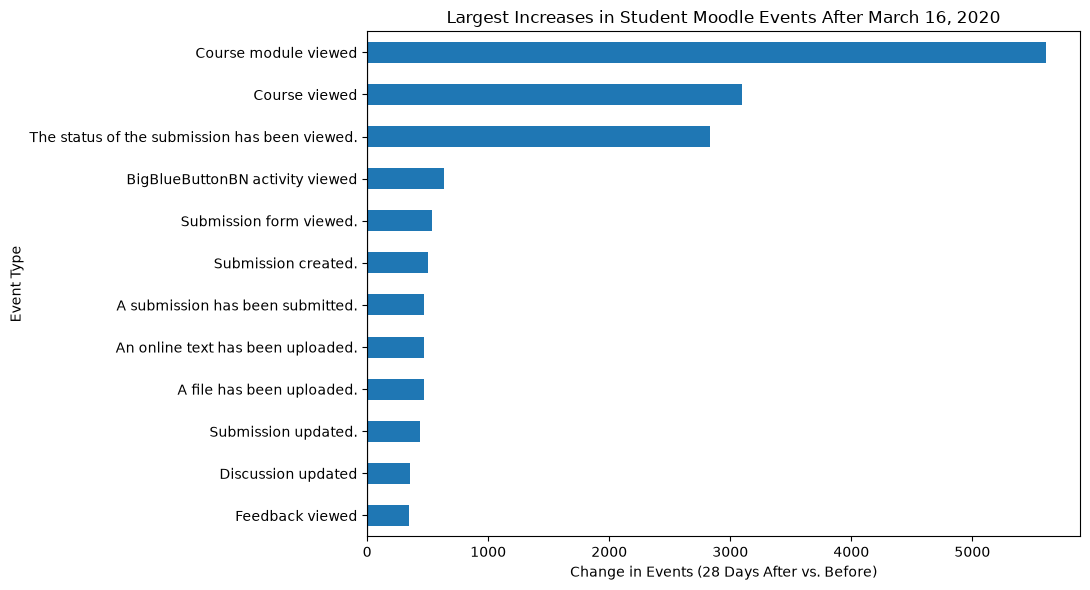

In [17]:
# Select the 12 largest increases
largest_student_increases = (
    student_covid_changes["Change"]
    .nlargest(12)
    .sort_values()
)

plt.figure(figsize=(11, 6))

largest_student_increases.plot(kind="barh")

plt.title("Largest Increases in Student Moodle Events After March 16, 2020")
plt.xlabel("Change in Events (28 Days After vs. Before)")
plt.ylabel("Event Type")
plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

#### Interpretation

The largest increases in student activity after March 16 occurred in course module viewing (+5,609 events), course viewing (+3,099) and viewing submission statuses (+2,829).

Several assignment-related activities, including submission creation, file uploads and submission updates, also increased. BigBlueButton activity appeared after the transition, reflecting the introduction of online teaching activities.

These results suggest that the increase in Moodle usage was associated with greater course navigation, assignment-related interactions and online learning activities.

### 3.4 Changes in teacher activity types

We compare teacher Moodle events during the four weeks before and after the transition to remote teaching to identify which activities increased or decreased.

period,After,Before,Change
event_name,,,
Question updated,0,317,-317
Grader report viewed,21,148,-127
Question viewed,6,105,-99
Question category viewed,0,71,-71
Grading table viewed,189,57,132
Course module updated,226,83,143
BigBlueButtonBN activity viewed,169,0,169
The status of the submission has been viewed.,312,83,229
The submission has been graded.,258,0,258


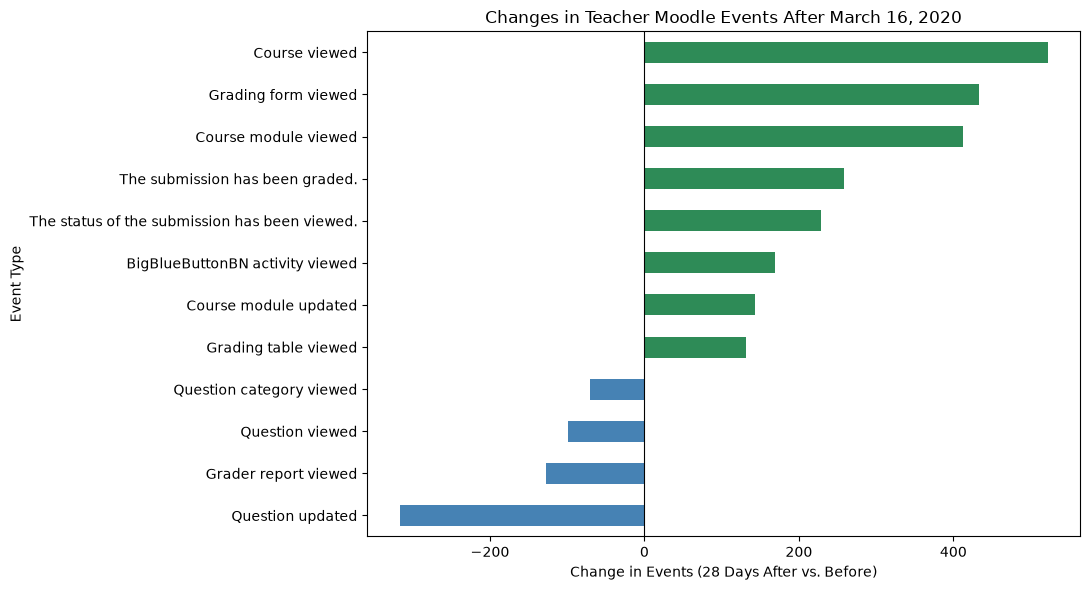

In [18]:
# Select teacher events
teacher_covid = covid_events[
    covid_events["actor_type"] == "Teachers"
].copy()

# Assign before/after periods
transition = pd.Timestamp("2020-03-16", tz="Europe/Tallinn")

teacher_covid["period"] = np.where(
    teacher_covid["event_time"] < transition,
    "Before",
    "After"
)

# Count events by type
teacher_covid_changes = pd.crosstab(
    teacher_covid["event_name"],
    teacher_covid["period"]
)

teacher_covid_changes["Change"] = (
    teacher_covid_changes["After"] -
    teacher_covid_changes["Before"]
)

# Display 12 largest changes in either direction
largest_teacher_changes = (
    teacher_covid_changes["Change"]
    .loc[lambda x: x.abs().nlargest(12).index]
    .sort_values()
)

display(teacher_covid_changes.loc[largest_teacher_changes.index])

# Plot increases and decreases
plt.figure(figsize=(11, 6))

largest_teacher_changes.plot(
    kind="barh",
    color=[
        "seagreen" if x > 0 else "steelblue"
        for x in largest_teacher_changes
    ]
)

plt.title("Changes in Teacher Moodle Events After March 16, 2020")
plt.xlabel("Change in Events (28 Days After vs. Before)")
plt.ylabel("Event Type")
plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

#### Interpretation

After March 16, 2020, teacher activity increased mainly in course navigation, grading and assignment-related events. The largest increases occurred in "Course viewed" (+522), "Grading form viewed" (+433) and "Course module viewed" (+413).

BigBlueButton activity also appeared after the transition, indicating the use of online teaching tools. Meanwhile, question editing and some grade-report viewing activities decreased.

These changes suggest that teachers' recorded Moodle activity shifted toward managing course materials, grading submissions and supporting remote teaching.

### 3.5 Overall findings

The transition to remote teaching coincided with much greater student Moodle activity and a smaller but notable increase in teacher activity. Both groups recorded more course-navigation events; students also showed more submission-related events, while teachers showed more grading activity. BigBlueButton events appeared after the transition, consistent with the move to online teaching.

## 4. Activity Around Assessments

Previous analysis showed that Moodle activity often peaks around certain weeks of the semester, potentially corresponding to assessments.

In this section, we use the course calendars from 2019–2026 to investigate how student activity changes around homework deadlines and examinations.

We aim to examine:
1. Whether student activity increases shortly before homework deadlines.
2. How activity changes around midterm and final examinations.
3. Whether these patterns differ across years.

### 4.1 Preparing the course calendars

We combine the yearly calendar files into one dataset and inspect the available activity types.

In [19]:
# Load and combine calendars from all years
calendar_list = []

for year in range(2019, 2027):
    df = pd.read_csv(DATA_DIR / str(year) / "calendar.csv")
    df["year"] = year
    calendar_list.append(df)

calendar = pd.concat(calendar_list, ignore_index=True)

# Check available calendar activity types
display(
    calendar.groupby(["year", "activity_type"])
    .size()
    .unstack(fill_value=0)
)

activity_type,final_exam,homework,lab,lecture,midterm_exam
year,,,,,
2019,3,12,75,15,3
2020,3,12,27,14,3
2021,3,12,30,14,3
2022,3,12,78,13,3
2023,3,12,72,12,3
2024,3,12,75,13,3
2025,3,11,70,12,3
2026,3,11,75,13,3


In [20]:
# Display calendar structure and example entries
print("Calendar columns:")
print(calendar.columns.tolist())

print("\nExample calendar entries:")
display(
    calendar[
        ["year", "activity_type", "activity_name", "start_time", "end_time"]
    ].head(15)
)

Calendar columns:
['course_run_id', 'activity_type', 'activity_name', 'start_time', 'end_time', 'year']

Example calendar entries:


,year,activity_type,activity_name,start_time,end_time
0,2019,lecture,lecture_01,2019-02-11T12:15:00+02:00,2019-02-11T14:00:00+02:00
1,2019,lecture,lecture_02,2019-02-18T12:15:00+02:00,2019-02-18T14:00:00+02:00
2,2019,lecture,lecture_03,2019-02-25T12:15:00+02:00,2019-02-25T14:00:00+02:00
3,2019,lecture,lecture_04,2019-03-04T12:15:00+02:00,2019-03-04T14:00:00+02:00
4,2019,lecture,lecture_05,2019-03-11T12:15:00+02:00,2019-03-11T14:00:00+02:00
5,2019,lecture,lecture_06,2019-03-18T12:15:00+02:00,2019-03-18T14:00:00+02:00
6,2019,lecture,lecture_07,2019-03-25T12:15:00+02:00,2019-03-25T14:00:00+02:00
7,2019,lecture,lecture_08,2019-04-01T12:15:00+03:00,2019-04-01T14:00:00+03:00
8,2019,lecture,lecture_09,2019-04-08T12:15:00+03:00,2019-04-08T14:00:00+03:00
9,2019,lecture,lecture_11,2019-04-22T12:15:00+03:00,2019-04-22T14:00:00+03:00


### 4.2 Identifying homework deadlines

We extract homework deadlines from the course calendars and inspect their dates before comparing student activity around them.

In [21]:
# Select homework calendar entries
homework = calendar[
    calendar["activity_type"] == "homework"
].copy()

# Convert end times to local dates
homework["deadline"] = pd.to_datetime(
    homework["end_time"],
    utc=True
).dt.tz_convert("Europe/Tallinn").dt.date

# Inspect homework deadlines
display(
    homework[
        ["year", "activity_name", "start_time", "end_time", "deadline"]
    ].head(15)
)

# Check number of unique deadline dates per year
display(
    homework.groupby("year")["deadline"]
    .nunique()
    .rename("Unique deadline dates")
)

,year,activity_name,start_time,end_time,deadline
90,2019,homework_01,NaN,2019-03-04T23:59:00+02:00,2019-03-04
91,2019,homework_02,NaN,2019-03-11T23:59:00+02:00,2019-03-11
92,2019,homework_03,NaN,2019-03-18T23:59:00+02:00,2019-03-18
93,2019,homework_04,NaN,2019-03-25T23:59:00+02:00,2019-03-25
94,2019,homework_05,NaN,2019-04-01T23:59:00+03:00,2019-04-01
95,2019,homework_06,NaN,2019-04-08T23:59:00+03:00,2019-04-08
96,2019,homework_07,NaN,2019-04-15T23:59:00+03:00,2019-04-15
97,2019,homework_08,NaN,2019-05-06T23:59:00+03:00,2019-05-06
98,2019,homework_09,NaN,2019-05-13T23:59:00+03:00,2019-05-13
99,2019,homework_10,NaN,2019-05-20T23:59:00+03:00,2019-05-20


year
2019    12
2020    12
2021    12
2022    12
2023    12
2024    12
2025    11
2026    11
Name: Unique deadline dates, dtype: int64

### 4.3 Student activity around homework deadlines

We compare student Moodle activity on homework deadline days, during the two days before deadlines, and on other days.

Activity is measured as daily events per enrolled student to account for differences in cohort size across years.

In [22]:
# Daily student events per enrolled student
student_daily = students.copy()

student_daily["date"] = (
    student_daily["event_time"]
    .dt.tz_localize(None)
    .dt.normalize()
)

daily_counts = (
    student_daily.groupby(["year", "date"])
    .size()
    .rename("events")
    .reset_index()
)

daily_counts["events_per_student"] = (
    daily_counts["events"] /
    daily_counts["year"].map(student_counts)
)

# Keep only the period between the first and last homework deadline
homework_periods = homework.groupby("year")["deadline"].agg(
    ["min", "max"]
)

daily_counts = daily_counts[
    daily_counts.apply(
        lambda row:
            pd.Timestamp(homework_periods.loc[row["year"], "min"])
            <= row["date"]
            <= pd.Timestamp(homework_periods.loc[row["year"], "max"]),
        axis=1
    )
].copy()

# Classify dates relative to homework deadlines
deadline_dates = {
    year: set(pd.to_datetime(group["deadline"]))
    for year, group in homework.groupby("year")
}

def classify_deadline_day(row):
    dates = deadline_dates[row["year"]]
    date = row["date"]

    if date in dates:
        return "Deadline day"
    if any(date + pd.Timedelta(days=i) in dates for i in [1, 2]):
        return "1–2 days before"
    return "Other days"

daily_counts["period"] = daily_counts.apply(
    classify_deadline_day,
    axis=1
)

# Compare average activity
deadline_comparison = (
    daily_counts.groupby(["year", "period"])["events_per_student"]
    .mean()
    .unstack()
)

display(deadline_comparison.round(2))

period,1–2 days before,Deadline day,Other days
year,,,
2019,2.74,14.07,2.09
2020,7.72,23.24,6.41
2021,6.64,22.33,8.77
2022,6.71,23.33,4.72
2023,8.91,21.41,4.49
2024,7.64,26.26,6.91
2025,4.79,16.25,3.56
2026,4.93,14.31,3.08


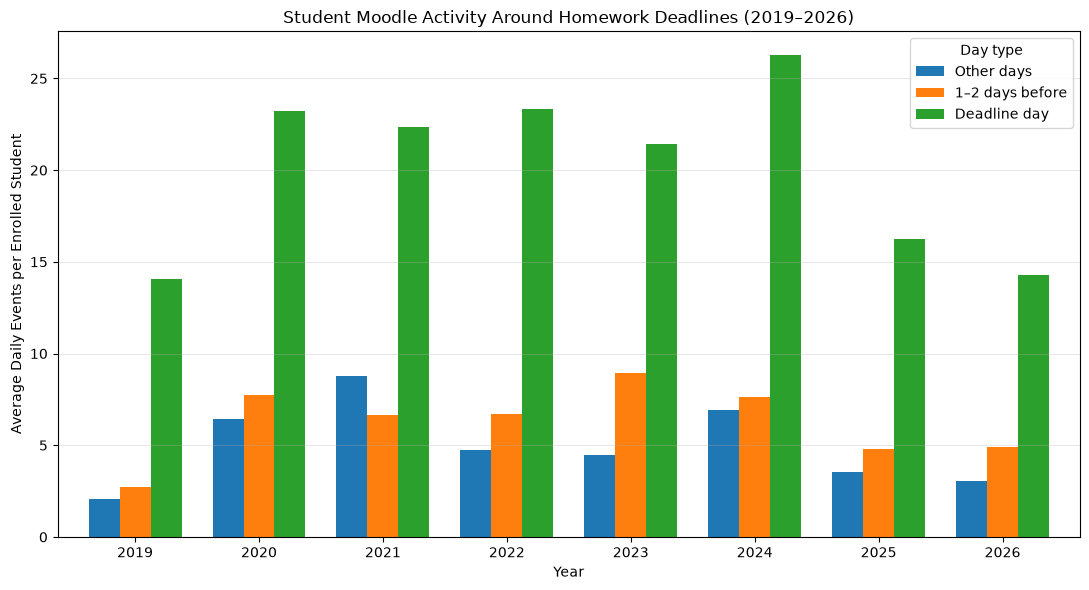

In [23]:
# Compare student activity around deadlines
ax = deadline_comparison[
    ["Other days", "1–2 days before", "Deadline day"]
].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

plt.title("Student Moodle Activity Around Homework Deadlines (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Average Daily Events per Enrolled Student")
plt.xticks(rotation=0)
plt.legend(title="Day type")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Interpretation

Across all eight years, student Moodle activity was consistently highest on homework deadline days, averaging approximately 14–26 events per enrolled student. Activity was also generally higher during the two days before deadlines than on other days within the homework period.

This consistent pattern suggests that students' recorded Moodle interactions are strongly concentrated around assignment deadlines, despite changes in teaching arrangements and overall activity levels.

### 4.4 Student activity around examinations

We examine student Moodle activity around midterm and final examinations from 2019 to 2026.

We compare activity during the two days before an exam, on the exam day, and during the two days afterward to identify whether examinations are associated with increased Moodle activity.

In [24]:
# Select midterm and final examinations
exams = calendar[
    calendar["activity_type"].isin(["midterm_exam", "final_exam"])
].copy()

# Convert exam start and end times to local dates
for col in ["start_time", "end_time"]:
    exams[col] = pd.to_datetime(
        exams[col],
        utc=True
    ).dt.tz_convert("Europe/Tallinn")

# Inspect exam dates
display(
    exams[
        ["year", "activity_type", "activity_name",
         "start_time", "end_time"]
    ].head(18)
)

,year,activity_type,activity_name,start_time,end_time
102,2019,midterm_exam,midterm_attempt_1,2019-04-15 12:15:00+03:00,2019-04-15 14:00:00+03:00
103,2019,midterm_exam,midterm_attempt_2,2019-06-04 16:35:00+03:00,2019-06-04 18:20:00+03:00
104,2019,midterm_exam,midterm_attempt_3,2019-06-10 16:35:00+03:00,2019-06-10 18:20:00+03:00
105,2019,final_exam,final_attempt_1,2019-06-04 14:15:00+03:00,2019-06-04 16:15:00+03:00
106,2019,final_exam,final_attempt_2,2019-06-10 14:15:00+03:00,2019-06-10 16:15:00+03:00
107,2019,final_exam,final_attempt_3,2019-06-17 14:15:00+03:00,2019-06-17 16:15:00+03:00
161,2020,midterm_exam,midterm_attempt_1,2020-04-17 12:15:00+03:00,2020-04-17 14:15:00+03:00
162,2020,midterm_exam,midterm_attempt_2,2020-05-29 15:15:00+03:00,2020-05-29 17:15:00+03:00
163,2020,midterm_exam,midterm_attempt_3,2020-06-12 15:15:00+03:00,2020-06-12 17:15:00+03:00
164,2020,final_exam,final_attempt_1,2020-05-29 12:15:00+03:00,2020-05-29 14:15:00+03:00


### 4.5 Student activity around exam days

We compare student Moodle activity before, during and after scheduled examination days.

Activity is measured as daily events per enrolled student. Each exam day is counted only once, even if multiple examination sessions overlap.

In [25]:
# Extract exam dates
exams["exam_date"] = (
    exams["start_time"]
    .dt.tz_localize(None)
    .dt.normalize()
)

exam_dates = {
    year: set(group["exam_date"])
    for year, group in exams.groupby("year")
}

# Classify daily activity relative to exams
def classify_exam_day(row):
    dates = exam_dates[row["year"]]
    date = row["date"]

    if date in dates:
        return "Exam day"
    if any(date + pd.Timedelta(days=i) in dates for i in [1, 2]):
        return "1–2 days before"
    if any(date - pd.Timedelta(days=i) in dates for i in [1, 2]):
        return "1–2 days after"
    return "Other days"

# Rebuild daily activity across the full observed course period.
# The homework analysis restricted daily_counts to its deadline window.
exam_daily = (
    student_daily.groupby(["year", "date"])
    .size()
    .rename("events")
    .reset_index()
)
exam_daily["events_per_student"] = (
    exam_daily["events"] / exam_daily["year"].map(student_counts)
)

exam_daily["exam_period"] = exam_daily.apply(
    classify_exam_day,
    axis=1
)

exam_comparison = (
    exam_daily.groupby(["year", "exam_period"])["events_per_student"]
    .mean()
    .unstack()
)

display(exam_comparison.round(2))

exam_period,1–2 days after,1–2 days before,Exam day,Other days
year,,,,
2019,1.92,5.11,8.21,2.94
2020,2.64,13.94,36.94,6.16
2021,4.76,9.59,40.16,6.66
2022,2.86,11.90,46.04,4.71
2023,2.62,9.02,9.97,6.01
2024,3.28,12.15,7.98,7.37
2025,2.20,9.84,7.48,3.85
2026,2.26,11.98,7.91,3.37


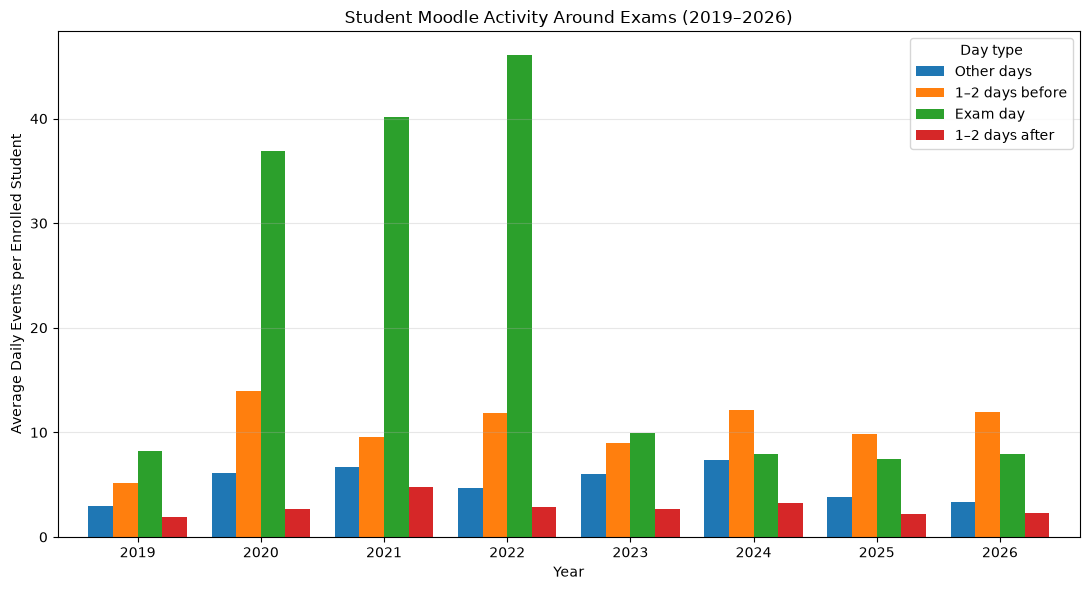

In [26]:
# Compare student activity around exam days
ax = exam_comparison[
    ["Other days", "1–2 days before", "Exam day", "1–2 days after"]
].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Student Moodle Activity Around Exams (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Average Daily Events per Enrolled Student")
plt.xticks(rotation=0)
plt.legend(title="Day type")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Interpretation

The earlier exam-day comparison showed much higher activity in 2020–2022 than in the other years, consistent with greater use of online assessment during and shortly after remote teaching. Activity was often elevated before examinations and lower afterward.

### 4.6 Overall findings

Homework deadline days had the highest recorded student activity across all eight years, while exam-day patterns varied more by year. In particular, exam-day activity was much higher during 2020–2022 than in the other years. These comparisons show how the timing of assessments relates to Moodle activity, without establishing that each peak was caused by an assessment alone.

## 5. Overall Conclusions

- **Changes after 2024:** The unusual student-activity peak was strongly influenced by `Quiz attempt updated`. The subsequent decline affected both quiz events and course navigation, while changes in 2026 were more mixed.
- **Different teacher patterns:** Quiz reviewing, grading, and submission-management events changed in different directions across 2023–2026; teachers did not simply follow the student trend.
- **COVID-19 transition:** Student and teacher activity increased after March 16, 2020, particularly among students. Both course navigation and assessment-related interactions changed.
- **Assessment schedules:** Homework deadline days consistently generated much more recorded activity than ordinary days. Exam days were especially active in 2020–2022.

### Interpretation and limitations

The notebooks demonstrate why **recorded Moodle event counts are not the same as participation, study time, or teacher workload**. For example, quiz participation stayed around 95–97% even as quiz event counts changed sharply. Differences in Moodle logging, tools, and course design can also affect year-to-year comparisons. The before/after COVID-19 comparison is descriptive and does not isolate a causal effect; likewise, any connection to students' use of large language models remains unverified.

Some exam dates may coincide with homework deadlines, so exam-day differences should not be attributed exclusively to examinations.

### Takeaway

Moodle activity was shaped by teaching arrangements, assessment schedules, and the particular interactions recorded by the platform. Looking at event types, participation rates, and assessment dates explains much more than comparing annual totals alone.